In [1]:
from bikeroot import BikeNetwork, CostApplicator, Cost, NgaMobrp_Cost, NGAMOBRPProblem, alg_utils, NGAMOBRPCrossover, NGAMOBRPMutation, NGAMOBRPSampling, NGAMOBRPSurvival, NGAMOBRPSelection, RouteDuplicateElim
from pymoo.termination import get_termination
from pymoo.core.callback import Callback
from pymoo.optimize import minimize

from pymoo.core.evaluator import Evaluator
import osmnx as ox
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.core.population import Population

import numpy as np
location = "Spokane, WA"
meters = 1000
location_name = location.split(",")[0].lower()
bike_net = BikeNetwork(location)
bike_net = BikeNetwork(location)
bike_net.load_graph(f'data/{location_name}_{meters}_cost.graphml')
if "crs" not in bike_net.graph.graph:
    bike_net.graph.graph["crs"] = "EPSG:4326"
bike_net.prints("edges", 10)

Number of edges: 11063

Edges:
(48925897, 11017100072, {'travel distance': '5.020851945953341', 'travel time': '0.8676087689568587', 'safety': '5.775874464070789', 'comfort': '5.775874464070789', 'length': 5.020851945953341})
(48925897, 11017100074, {'travel distance': '4.04068512071489', 'travel time': '0.6982348575626215', 'safety': '4.648312728061632', 'comfort': '4.648312728061632', 'length': 4.04068512071489})
(48925897, 11017100071, {'travel distance': '13.476898466951406', 'travel time': '2.328822959556144', 'safety': '15.503519033831866', 'comfort': '15.503519033831866', 'length': 13.476898466951406})
(50870112, 8582133301, {'travel distance': '9.4799377034922', 'travel time': '1.8751093157115473', 'safety': '10.681634932484855', 'comfort': '17.62469763860001', 'length': 9.4799377034922})
(50870112, 51029470, {'travel distance': '167.9671349736185', 'travel time': '29.31568072277656', 'safety': '194.64107870298398', 'comfort': '194.64107870298398', 'length': 167.9671349736185})

In [2]:
bike_net.prints("nodes", 10)

Number of nodes: 3760

Nodes:
(48925897, {'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6571934, 'x': -117.42351})
(50870112, {'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6513773, 'x': -117.4295205})
(50870128, {'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6571576, 'x': -117.429601})
(50870129, {'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6565353, 'x': -117.4295939})
(50870130, {'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6559688, 'x': -117.4295825})
(50870132, {'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6544675, 'x': -117.4295634})
(50870133, {'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6534274, 'x': -117.4295416})
(50870140, {'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6503118, 'x': -117.4295166})
(50870141, {'time pena

In [3]:
src = 48925897
dst = 7178743943
path = alg_utils.a_star(bike_net.graph, src, dst, weight='travel distance')
# print(path)
# ox.plot_graph_route(bike_net.graph, path)

for node in path:
    print(bike_net.graph.nodes[node])

{'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6571934, 'x': -117.42351}
{'time penalty': '4', 'safety penalty': '160', 'comfort penalty': '120', 'y': 47.6571153, 'x': -117.4235048}
{'time penalty': '4', 'safety penalty': '160', 'comfort penalty': '120', 'y': 47.6566598, 'x': -117.4234917}
{'time penalty': '2', 'safety penalty': '100', 'comfort penalty': '70', 'y': 47.6565652, 'x': -117.4234898}
{'time penalty': '4', 'safety penalty': '160', 'comfort penalty': '120', 'y': 47.6564809, 'x': -117.4234888}
{'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6560193, 'x': -117.4234887}
{'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6559226, 'x': -117.4234879}
{'time penalty': '0', 'safety penalty': '0', 'comfort penalty': '0', 'y': 47.6550063, 'x': -117.4234749}
{'time penalty': '4', 'safety penalty': '100', 'comfort penalty': '120', 'y': 47.6545839, 'x': -117.423468}
{'time penalty': '0', 'safety penalt

In [4]:
seed = 1
problem = NGAMOBRPProblem(bike_net.graph,src, dst ,seed=seed)

algorithm = NSGA2(
    pop_size   = 100,
    sampling   = NGAMOBRPSampling(100),
    crossover  = NGAMOBRPCrossover(),
    mutation   = NGAMOBRPMutation(),
    selection  = NGAMOBRPSelection(),
    eliminate_duplicates = RouteDuplicateElim(problem)
)

class DebugCB(Callback):
    def __init__(self):
        super().__init__()
    def notify(self, algorithm):
        gen = algorithm.n_gen
        print(f"Gen {gen:02d} | pop.F[0] = {algorithm.pop.get('F')[0]}")


termination = get_termination("n_gen", 200)

res = minimize(
    problem,                  # your NGAMOBRPProblem
    algorithm,
    termination,
    callback = DebugCB(),     # drop if you don’t want console spam
    seed     = seed,
    verbose  = True           # prints generational stats
)

n_gen  |  n_eval  | n_nds  |      eps      |   indicator  
     1 |      100 |     27 |             - |             -
Gen 01 | pop.F[0] = [ 890.74527415  180.32194086 2019.07991286 1785.46414636]
     2 |      200 |     32 |  0.3155303632 |         ideal
Gen 02 | pop.F[0] = [ 884.04662249  178.82630321 1997.28417518 1827.28417518]
     3 |      300 |     69 |  0.000000E+00 |             f
Gen 03 | pop.F[0] = [ 884.04662249  178.82630321 1997.28417518 1827.28417518]
     4 |      400 |    100 |  0.000000E+00 |             f
Gen 04 | pop.F[0] = [ 878.12687353  185.33259428 2265.91215677 1961.4256282 ]
     5 |      500 |    100 |  0.1893823969 |         ideal
Gen 05 | pop.F[0] = [ 878.12687353  185.33259428 2265.91215677 1961.4256282 ]
     6 |      600 |    100 |  0.000000E+00 |             f
Gen 06 | pop.F[0] = [ 897.63688307  177.61279124 1810.98521938 1658.43326513]
     7 |      700 |    100 |  0.000000E+00 |             f
Gen 07 | pop.F[0] = [ 885.58064692  175.8269994  1897.140373


Found unique Route 1 objectives: [ 891.18511611  182.28651678 1560.28049115 1588.9898058 ]

Found unique Route 2 objectives: [ 874.63922559  176.58068653 1997.2510248  1781.25758957]

Found unique Route 3 objectives: [ 882.40704232  169.96036941 1618.46655906 1534.78163684]

Found unique Route 4 objectives: [ 894.46327847  171.74616125 1532.31140523 1478.62648301]

Found unique Route 5 objectives: [ 891.39862649  172.38192447 1588.34072194 1474.53440159]


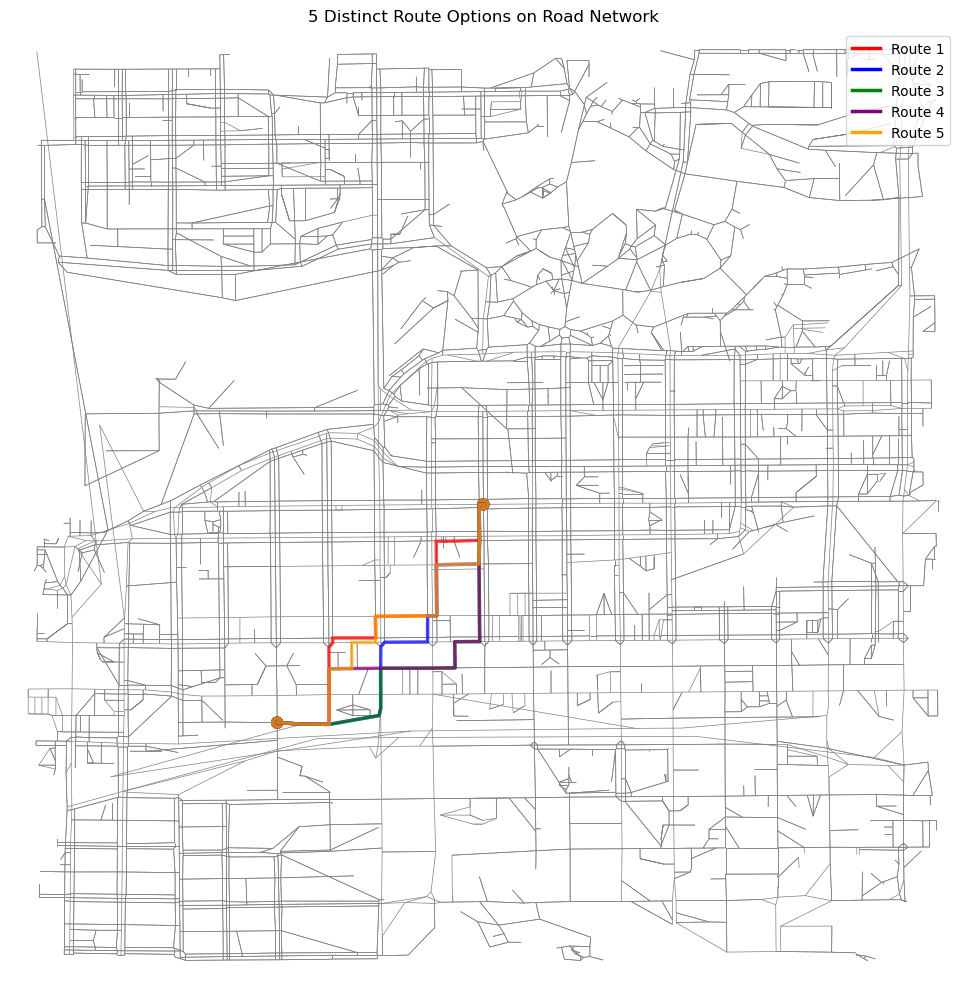

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Plot the base road network and overlay multiple distinct routes
final_pop = res.pop
max_routes_to_plot = 5

# Create a figure and axis
fig, ax = plt.subplots(figsize=(15, 10))

# Plot the base graph
ox.plot_graph(bike_net.graph, ax=ax, node_size=0, edge_linewidth=0.5, 
              edge_color='gray', show=False, close=False) # show=False and close=False are key

# Define colors for routes
colors = ['red', 'blue', 'green', 'purple', 'orange']

# Store unique routes found
unique_routes = []
# Store the string representation of routes to check for uniqueness
unique_route_signatures = set()

# Iterate through the population to find distinct routes
for i in range(len(final_pop)):
    if len(unique_routes) >= max_routes_to_plot:
        break # Stop if we have enough unique routes

    route_index = int(final_pop[i].X[0])
    route = problem.get_route(route_index)
    
    # Create a string signature for the route to check for uniqueness
    route_signature = "_".join(map(str, route))

    if route_signature not in unique_route_signatures:
        unique_routes.append(route)
        unique_route_signatures.add(route_signature)
        print(f"\nFound unique Route {len(unique_routes)} objectives: {final_pop[i].F}")

# Plot the unique routes found
for idx, route in enumerate(unique_routes):
    ox.plot_graph_route(bike_net.graph, route, ax=ax, 
                      route_color=colors[idx % len(colors)],
                      route_linewidth=2.5, route_alpha=0.7,
                      orig_dest_size=80, node_size=0,
                      show=False, close=False) # Crucial to keep the same ax

# Add a legend
legend_elements = [plt.Line2D([0], [0], color=colors[i % len(colors)], 
                             label=f'Route {i+1}', 
                             linewidth=2.5) 
                  for i in range(len(unique_routes))]
ax.legend(handles=legend_elements, loc='upper right')

plt.title(f'{len(unique_routes)} Distinct Route Options on Road Network')
plt.tight_layout()
plt.show()

In [5]:
# problem = NGAMOBRPProblem(bike_net.graph,src, dst ,seed=4)
# sampler = NGAMOBRPSampling(10)
# X_init = sampler.do(problem, n_samples=10)   # pymoo wrapper around _do
# X_mut = NGAMOBRPMutation(prob=1.0).do(problem, X_init, to_pop=True)   # prob=1.0 ⇒ every route is mutated once
# Evaluator().eval(problem, X_mut)
# X_sel = NGAMOBRPSelection().do(problem, X_mut, 5, 2, to_pop=True)
# X_cross = NGAMOBRPCrossover().do(problem, X_sel)